In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/superheated_vapor.csv')
df.head()

,Pressure,Property,Liq_Sat,Vap_Sat,75,100,125,150,175,200,...,425,450,475,500,525,550,575,600,625,650
0,1.0,V,1.000,129200.0000,160640.0000,172180.0000,183720.0000,195270.0000,206810.0000,218350.0000,...,NaN,333730.00,NaN,356810.0000,NaN,379880.0000,NaN,402960.0000,NaN,426040.0000
1,1.0,U,29.334,2385.2000,2480.8000,2516.4000,2552.3000,2588.5000,2624.9000,2661.7000,...,NaN,3049.90,NaN,3132.4000,NaN,3216.7000,NaN,3302.6000,NaN,3390.3000
2,1.0,H,29.335,2514.4000,2641.5000,2688.6000,2736.0000,2783.7000,2831.7000,2880.1000,...,NaN,3383.60,NaN,3489.2000,NaN,3596.5000,NaN,3705.6000,NaN,3816.4000
3,1.0,S,0.106,8.9767,9.3828,9.5136,9.6365,9.7527,9.8629,9.9679,...,NaN,10.82,NaN,10.9612,NaN,11.0957,NaN,11.2243,NaN,11.3476
4,10.0,V,1.010,14670.0000,16030.0000,17190.0000,18350.0000,19510.0000,20660.0000,21820.0000,...,NaN,33370.00,NaN,35670.0000,NaN,37980.0000,NaN,40290.0000,NaN,42600.0000


In [11]:
# Multiple Regression , Enthalpy H with Pressure, P and Temperature, T

H = df.loc[df["Property"] == "H"]
V = df.loc[df['Property'] == 'V']
U = df.loc[df['Property'] == 'U']
S = df.loc[df['Property'] == 'S']
H. shape


(136, 37)

In [3]:
H.head()

,Pressure,Property,Liq_Sat,Vap_Sat,75,100,125,150,175,200,...,425,450,475,500,525,550,575,600,625,650
2,1.0,H,29.335,2514.4,2641.5,2688.6,2736.0,2783.7,2831.7,2880.1,...,NaN,3383.6,NaN,3489.2,NaN,3596.5,NaN,3705.6,NaN,3816.4
6,10.0,H,191.832,2584.8,2640.0,2687.5,2735.2,2783.1,2831.2,2879.6,...,NaN,3383.5,NaN,3489.1,NaN,3596.5,NaN,3705.5,NaN,3816.3
10,20.0,H,251.453,2609.9,2638.4,2686.3,2734.2,2782.3,2830.6,2879.2,...,NaN,3383.4,NaN,3489.0,NaN,3596.4,NaN,3705.4,NaN,3816.2
14,30.0,H,289.302,2625.4,2636.8,2685.1,2733.3,2781.6,2830.0,2878.7,...,NaN,3383.3,NaN,3488.9,NaN,3596.3,NaN,3705.4,NaN,3816.2
18,40.0,H,317.650,2636.9,NaN,2683.8,2732.3,2780.9,2829.5,2878.2,...,NaN,3383.1,NaN,3488.8,NaN,3596.2,NaN,3705.3,NaN,3816.1


In [4]:
# There will be two input P and T and one output H.

X = H["Pressure"]
y = y = np.array([int(H.columns[4:][i]) for i in range(len(H.columns[4:]))])
Z = Z = H.loc[:, '75':'650']

In [5]:
y

array([ 75, 100, 125, 150, 175, 200, 220, 225, 240, 250, 260, 275, 280,
       290, 300, 320, 325, 340, 350, 360, 375, 380, 400, 425, 450, 475,
       500, 525, 550, 575, 600, 625, 650])

In [6]:
# Flatten the data
P_values = H['Pressure'].to_numpy()                              # (136,)
T_values = H.columns[4:].astype(int).to_numpy()                  # (33,)

# Turn it into a meshgrid 
P_grid, T_grid = np.meshgrid(P_values, T_values)                 # both (33, 136)
H_grid = H.loc[:, '75':'650'].to_numpy().T   
                    # (33, 136)
# Flatten 
P_flat = P_grid.ravel()      # (4488,)
T_flat = T_grid.ravel()      # (4488,)
H_flat = H_grid.ravel()      # (4488,)

# Remove NaN values
mask = ~np.isnan(H_flat)
P_clean = P_flat[mask]
T_clean = T_flat[mask]
H_clean = H_flat[mask]

print(P_flat.shape, mask.sum(), P_clean.shape)   # (4488,)  2063  (2063,)

(4488,) 2063 (2063,)


In [7]:
# Fit the multilinear Regression
import sys
sys.path.append("..") 
from functions import polynomial_model
from sklearn.metrics import mean_squared_error

# Fit the model
X_fit = np.column_stack((P_clean, T_clean))

for i in range(1, 4):
    model = polynomial_model(P_clean, T_clean, H_clean, i)
    lr = model.named_steps["linear_regression"]
    names = model.named_steps["polynomial_features"].get_feature_names_out(["P", "T"])
    y_pred = model.predict(X_fit)
    mse = mean_squared_error(H_clean, y_pred)
    rmse = np.sqrt(mse)

    print(f"Polynomial of degree {i}")
    print("R2 score:", model.score(X_fit, H_clean))
    print("MSE:", mse)
    for name, c in zip(names, lr.coef_):
        print(f"  {name}: {c:.4f}")
    print("Intercept:", lr.intercept_)
    print()


Polynomial of degree 1
R2 score: 0.9876784909472981
MSE: 1128.774185114659
  P: -58.2739
  T: 313.3289
Intercept: 3249.0192922927804

Polynomial of degree 2
R2 score: 0.9978173319626839
MSE: 199.95435012540506
  P: -68.1215
  T: 324.6884
  P^2: -0.0164
  P T: 35.8999
  T^2: -3.8265
Intercept: 3241.960347958279

Polynomial of degree 3
R2 score: 0.9995744023099568
MSE: 38.989029972741065
  P: -53.7137
  T: 327.7685
  P^2: -4.2741
  P T: 49.6892
  T^2: -15.5919
  P^3: 0.0245
  P^2 T: 3.1116
  P T^2: -21.2536
  T^3: 3.6911
Intercept: 3248.340373236339



In [8]:
# Adding in log features
import sys
sys.path.append("..") 
from features import log_feature_PT
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# X_fit = np.column_stack((P_clean, T_clean))
model_Hlog = Pipeline([
    ("log_basis", log_feature_PT()),
    ("scaler", StandardScaler()),
    ("linear_regression", LinearRegression()),
]).fit(X_fit, H_clean)

y_pred = model_Hlog.predict(X_fit)
print("R2:", model_Hlog.score(X_fit, H_clean))
print("RMSE:", np.sqrt(mean_squared_error(H_clean, y_pred)))
print(model_Hlog.named_steps["linear_regression"].coef_)

R2: 0.9941573213802574
RMSE: 23.135430396461317
[-61.80669685 222.04579263 -62.31898446 127.74451161]


In [9]:
# printing the coefficients
def print_equation(model, names):
    lr = model.named_steps["linear_regression"]
    sc = model.named_steps["scaler"]
    a = lr.coef_ / sc.scale_
    a0 = lr.intercept_ - np.sum(lr.coef_ * sc.mean_ / sc.scale_)
    print(f"a0: {a0:.4f}")
    for n, c in zip(names, a):
        print(f"{n}: {c:.6g}")

print_equation(model_Hlog, ["P", "T", "ln P", "T*ln P"])

a0: 2641.1620
P: -0.0191933
T: 1.60687
ln P: -38.7794
T*ln P: 0.0969206


Multivariate Regression: there is more than one output.

In [12]:
# Checking if the missing values in H , U and S are in the same corodinates
H_grid = H.loc[:, '75':'650'].to_numpy().T  
U_grid = U.loc[:, '75':'650'].to_numpy().T  

mask_H = ~np.isnan(H_grid.ravel())
mask_U = ~np.isnan(U_grid.ravel())
print(np.array_equal(mask_H, mask_U))

True


In [13]:
# Checking for H and S
S_grid = S.loc[:, '75':'650'].to_numpy().T 
mask_S = ~np.isnan(S_grid.ravel())
print(np.array_equal(mask_H, mask_S))

True


The NaN values are all the same, so we can clean the NaN values and use it for the multivariate  analysis

In [15]:

P_clean = P_flat[mask]
T_clean = T_flat[mask]
H_clean = H_flat[mask]
U_flat = U_grid.ravel()
U_clean = U_flat[mask_U]
S_flat = S_grid.ravel()
S_clean = S_flat[mask_S] 

In [16]:
S_clean.shape

(2063,)

In [17]:
# getting Y by stacking all three h, U and S
Y = np.column_stack((H_clean, U_clean, S_clean))
print(Y.shape)        # (2063, 3)

(2063, 3)


In [18]:
# Stack X also for P and T
X_fit = np.column_stack((P_clean, T_clean))      # (2063, 2)

model_multi_out = LinearRegression()
model_multi_out.fit(X_fit, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3, 2)","[[-0.02, 2.27], [-0.01, 1.76], [-0. , 0. ]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](3,)","[2380.27,2273.74, 6.63]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[146276.13, 5979.52]"


In [20]:
y_pred_multi = model_multi_out.predict(X_fit)
R2_multivariate = model_multi_out.score(X_fit, Y)
print(R2_multivariate)


0.8803086865299331


In [ ]:
from sklearn.metrics import r2_score

print(r2_score(Y, y_pred_multi, multioutput="raw_values"))   # one R² per column

[0.98767849 0.9878924  0.66535517]


In [22]:
print("coef_ shape:", model_multi_out.coef_.shape)
print("intercept_ shape:", model_multi_out.intercept_.shape)

outputs = ["H", "U", "S"]          # same order as the columns of Y
features = ["P", "T"]              # same order as the columns of X_fit

for i, out in enumerate(outputs):
    print(f"\n{out}:")
    print(f"  intercept: {model_multi_out.intercept_[i]:.4f}")
    for j, feat in enumerate(features):
        print(f"  {feat}: {model_multi_out.coef_[i, j]:.6g}")

coef_ shape: (3, 2)
intercept_ shape: (3,)

H:
  intercept: 2380.2653
  P: -0.0180962
  T: 2.26745

U:
  intercept: 2273.7414
  P: -0.0136728
  T: 1.75755

S:
  intercept: 6.6278
  P: -0.000194471
  T: 0.00298324


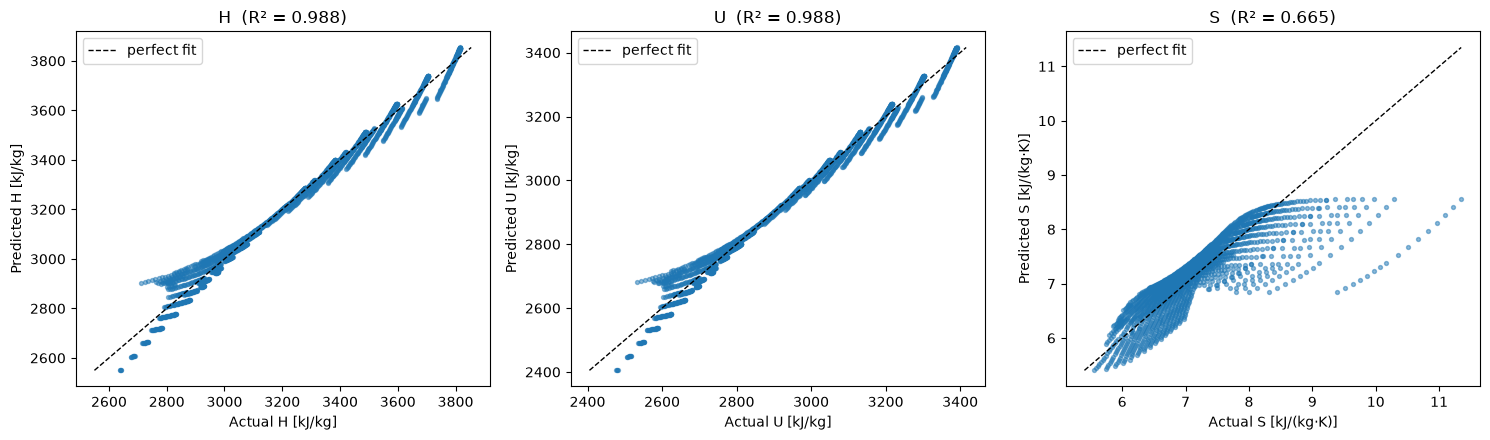

In [24]:
import matplotlib.pyplot as plt
outputs = ["H", "U", "S"]
units = ["kJ/kg", "kJ/kg", "kJ/(kg·K)"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, ax in enumerate(axes):
    actual, pred = Y[:, i], y_pred_multi[:, i]
    ax.scatter(actual, pred, s=8, alpha=0.5)
    lims = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
    ax.plot(lims, lims, "k--", linewidth=1, label="perfect fit")
    ax.set_xlabel(f"Actual {outputs[i]} [{units[i]}]")
    ax.set_ylabel(f"Predicted {outputs[i]} [{units[i]}]")
    ax.set_title(f"{outputs[i]}  (R² = {r2_score(actual, pred):.3f})")
    ax.legend()

plt.tight_layout()
plt.show()

In [25]:
import sys
sys.path.append("..")
from features import log_feature_PT
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# X_fit = np.column_stack((P_clean, T_clean))
model_Slog = Pipeline([
    ("log_basis", log_feature_PT()),
    ("scaler", StandardScaler()),
    ("linear_regression", LinearRegression()),
]).fit(X_fit, S_clean)

y_pred = model_Slog.predict(X_fit)
print("R2:", model_Slog.score(X_fit, S_clean))
print("RMSE:", np.sqrt(mean_squared_error(S_clean, y_pred)))
print(model_Slog.named_steps["linear_regression"].coef_)




R2: 0.9948141151704862
RMSE: 0.05620653570512341
[-0.06702453  0.42028687 -0.76152928  0.06404343]


In [26]:
sc = model_Slog.named_steps["scaler"]
sc.mean_      # μ for each feature, in your column order
sc.scale_     # σ for each feature

array([3.22023010e+03, 1.38185651e+02, 1.60701053e+00, 1.31803313e+03])

In [37]:

import importlib
import features
importlib.reload(features)
from features import log_feature_PT_K
from features import log_feature_PT_K

model_Slog = Pipeline([
    ("log_basis", log_feature_PT_K()),
    ("scaler", StandardScaler()),
    ("linear_regression", LinearRegression()),
]).fit(X_fit, S_clean)

y_pred = model_Slog.predict(X_fit)
print("R2:", model_Slog.score(X_fit, S_clean))
print("RMSE:", np.sqrt(mean_squared_error(S_clean, y_pred)))
print(model_Slog.named_steps["linear_regression"].coef_)

R2: 0.9961575556743338
RMSE: 0.04838148300540371
[-0.05572484  0.18114949 -0.75308086  0.29093369]


In [38]:
lr = model_Slog.named_steps["linear_regression"]
print("Coefficients: ", lr.coef_)
print("Intercept: ", lr.intercept_)
  


Coefficients:  [-0.05572484  0.18114949 -0.75308086  0.29093369]
Intercept:  7.174352011633598


In [39]:
sc = model_Slog.named_steps["scaler"]
print("Mean: ", sc.mean_ ) 
print("Scale: ", sc.scale_)

Mean:  [3494.72655114  411.03247698    7.42107913    6.50687155]
Scale:  [3.22023010e+03 1.38185651e+02 1.60701053e+00 2.09609915e-01]


In [40]:
# Building back the equation
b  = lr.coef_            # standardized coefficients, shape (4,)
b0 = lr.intercept_       # standardized intercept
mu = sc.mean_            # shape (4,)
sd = sc.scale_           # shape (4,)

a  = b / sd                         # element-wise division, original-unit coefficients
a0 = b0 - np.sum(b * mu / sd)       # original-unit intercept

names = ["P", "T", "ln P", "ln T"]
for n, c in zip(names, a):
    print(f"{n}: {c:.6g}")
print("intercept:", a0)

P: -1.73046e-05
T: 0.00131091
ln P: -0.468622
ln T: 1.38798
intercept: 1.1422947995569235


In [41]:
x = np.array([1000.0, 300.0, np.log(1000.0), np.log(300 + 273.15)])   # P, T, ln P, ln T
print(a0 + a @ x)
print(model_Slog.predict([[1000.0, 300.0]])[0])      # should match

7.096381828220759
7.096381828220759


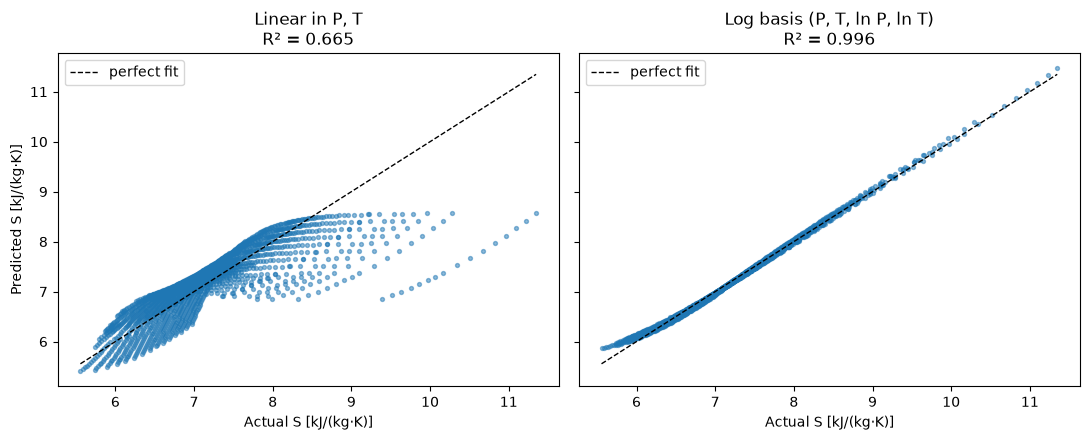

In [42]:
# Predictions from the two models
S_pred_lin = model_multi_out.predict(X_fit)[:, 2]     # linear plane in P, T (S is column 2)
S_pred_log = model_Slog.predict(X_fit)                # log model with ln P, ln T

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
panels = [(S_pred_lin, "Linear in P, T"), (S_pred_log, "Log basis (P, T, ln P, ln T)")]

lims = [S_clean.min(), S_clean.max()]
for ax, (pred, title) in zip(axes, panels):
    ax.scatter(S_clean, pred, s=8, alpha=0.5)
    ax.plot(lims, lims, "k--", linewidth=1, label="perfect fit")
    ax.set_title(f"{title}\nR² = {r2_score(S_clean, pred):.3f}")
    ax.set_xlabel("Actual S [kJ/(kg·K)]")
    ax.legend()
axes[0].set_ylabel("Predicted S [kJ/(kg·K)]")

plt.tight_layout()
plt.show()